# Smart Campus Energy Consumption Tracker & Analyzer
PIYUSH TAK,
HIMESH KUMAR PRAJAPATI,
MOKSH JAIN

Synthetic demonstration, following the nine-stage supplied workflow. Run from the extracted project folder after installing requirements.

## 1. Problem definition
Identify peak hourly consumption, unusual readings, and conditional saving opportunities. Anomalies require investigation; they are not automatically wastage.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from energy import generate_data, clean_data, make_features, train_evaluate, forecast, recommendations

## 2. Dataset creation
120 days, five synthetic buildings; seeded reproducibility.

In [2]:
raw = generate_data()
raw.head()

,timestamp,building,energy_kwh,occupancy,appliances_on,temperature_c,is_holiday,injected_anomaly
0,2025-01-01 00:00:00,Academic Block,18.257,7,10,22.51,0,0
1,2025-01-01 01:00:00,Academic Block,16.694,0,5,22.28,0,0
2,2025-01-01 02:00:00,Academic Block,14.558,10,5,21.37,0,0
3,2025-01-01 03:00:00,Academic Block,14.710,11,11,21.71,0,0
4,2025-01-01 04:00:00,Academic Block,13.899,0,3,20.24,0,0


## 3. Data collection
Replace generated data with pd.read_csv("your_data.csv") for real campus measurements. Required fields: timestamp, building, energy_kwh (hourly interval energy, not cumulative reading).

In [3]:
raw.shape, raw.dtypes

((14400, 8),
 timestamp           datetime64[ns]
 building                    object
 energy_kwh                 float64
 occupancy                    int64
 appliances_on                int64
 temperature_c              float64
 is_holiday                   int64
 injected_anomaly             int64
 dtype: object)

## 4. Data cleaning
Past-only limited fills; preserve original observation flags.

In [4]:
clean, quality = clean_data(raw)
quality

{'input_rows': 14400,
 'invalid_keys_removed': 0,
 'duplicate_rows_removed': 0,
 'invalid_or_missing_energy': 70,
 'missing_hour_rows_added': 0,
 'output_rows': 14400,
 'unfilled_energy_rows': 0}

## 5. Exploratory data analysis

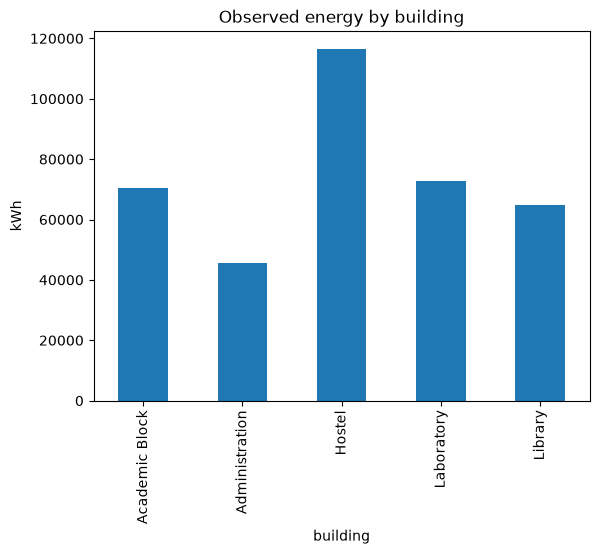

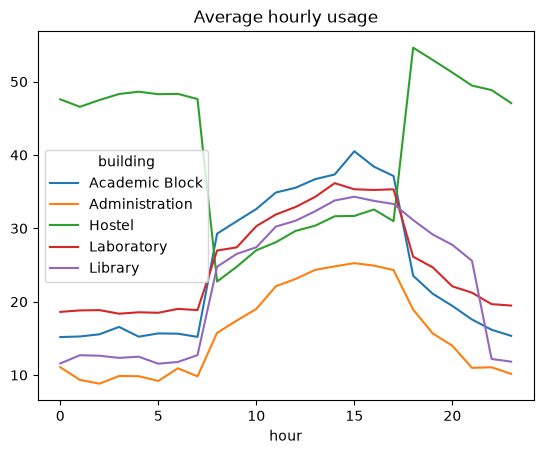

weekend
False    26.667320
True     23.702854
Name: energy_kwh, dtype: float64

In [5]:
observed = clean[clean.energy_observed].copy()
observed.groupby('building').energy_kwh.sum().plot.bar(title='Observed energy by building', ylabel='kWh'); plt.show()
observed.assign(hour=observed.timestamp.dt.hour).groupby(['hour','building']).energy_kwh.mean().unstack().plot(title='Average hourly usage'); plt.show()
observed.assign(weekend=observed.timestamp.dt.dayofweek>=5).groupby('weekend').energy_kwh.mean()

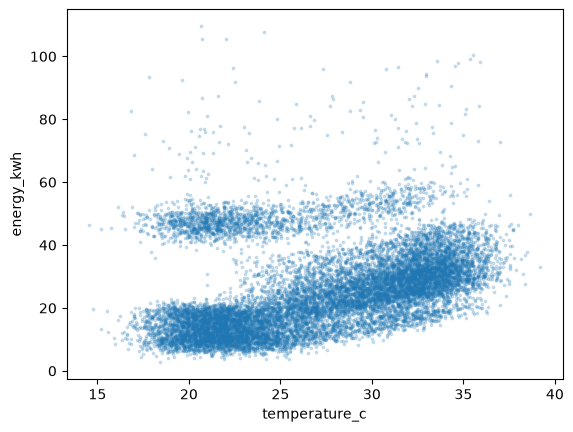

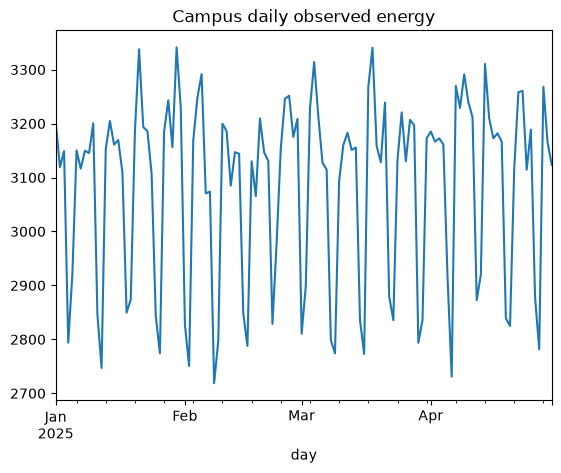

In [6]:
observed.plot.scatter(x='temperature_c', y='energy_kwh', s=3, alpha=.2); plt.show()
observed.assign(day=observed.timestamp.dt.floor('d')).groupby('day').energy_kwh.sum().plot(title='Campus daily observed energy'); plt.show()

## 6. Feature engineering
All rolling features are shifted before aggregation; future occupancy and weather are not assumed known.

In [7]:
features = make_features(clean)
features.head(175).tail()

,timestamp,building,energy_kwh,occupancy,appliances_on,temperature_c,is_holiday,injected_anomaly,energy_observed,hour_sin,hour_cos,weekday,month,is_weekend,lag_1,lag_24,lag_168,rolling_24
170,2025-01-08 02:00:00,Academic Block,13.222,2,5,21.73,0,0,True,0.500000,8.660254e-01,2,1,0,15.477,16.548,14.558,26.989208
171,2025-01-08 03:00:00,Academic Block,18.392,8,5,18.60,0,0,True,0.707107,7.071068e-01,2,1,0,13.222,16.817,14.710,26.850625
172,2025-01-08 04:00:00,Academic Block,14.658,3,4,18.88,0,0,True,0.866025,5.000000e-01,2,1,0,18.392,14.993,13.899,26.916250
173,2025-01-08 05:00:00,Academic Block,13.953,0,3,20.82,0,0,True,0.965926,2.588190e-01,2,1,0,14.658,15.285,12.837,26.902292
174,2025-01-08 06:00:00,Academic Block,15.340,0,1,21.37,0,0,True,1.000000,6.123234e-17,2,1,0,13.953,13.038,14.257,26.846792


## 7. Modeling
Chronological holdout; rolling one-hour-ahead evaluation. Production forecasting model is refit afterwards.

In [8]:
fitted = train_evaluate(clean)
pd.DataFrame({k:v for k,v in fitted['scores'].items() if isinstance(v,dict)})

,random_forest,previous_day_baseline
MAE_kWh,3.314594,4.868577
RMSE_kWh,6.670329,9.684754
R2,0.762933,0.500250


## 8. Prediction visualization

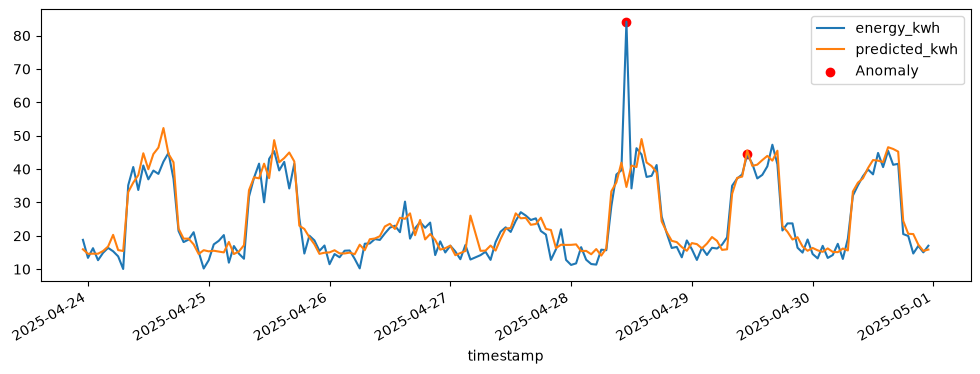

In [10]:
test = fitted['test']
view = test[test.building=='Academic Block'].tail(168)
ax = view.set_index('timestamp')[['energy_kwh','predicted_kwh']].plot(figsize=(12,4))
alerts = view[view.anomaly]
ax.scatter(alerts.timestamp, alerts.energy_kwh, color='red', label='Anomaly')
ax.legend(); plt.show()

## 9. Dashboard and final output
Launch with `python -m streamlit run app.py`. Conditional savings below cover the holdout period only; tariff=8 and recovery=25% are assumptions.

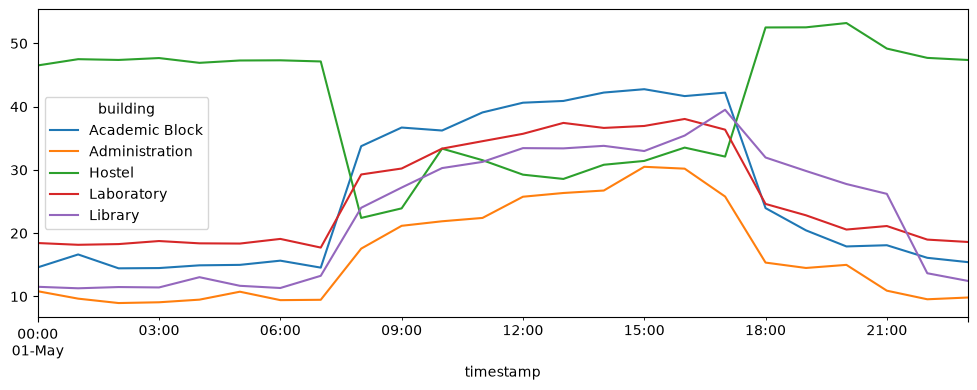

,building,review_alerts,flagged_positive_excess_kwh,scenario_recoverable_kwh,scenario_saving_inr,action
0,Academic Block,1,49.53,12.38,99.06,"Review alert timestamps, occupancy, HVAC sched..."
1,Administration,2,65.06,16.27,130.13,"Review alert timestamps, occupancy, HVAC sched..."
2,Hostel,26,287.19,71.80,574.38,"Review alert timestamps, occupancy, HVAC sched..."
3,Laboratory,4,204.20,51.05,408.40,"Review alert timestamps, occupancy, HVAC sched..."
4,Library,6,258.42,64.60,516.83,"Review alert timestamps, occupancy, HVAC sched..."


In [11]:
future = forecast(clean, fitted, hours=24)
future.pivot(index='timestamp', columns='building', values='forecast_kwh').plot(figsize=(12,4)); plt.show()
recommendations(test, tariff=8, recoverable_fraction=.25)

## Limitations
Synthetic data do not establish real campus performance. One-hour holdout scores do not measure recursive 24-hour forecast accuracy. Anomaly flags are not proof of waste. See README for input requirements and limitations.